# Predicting mortgage default from the loan application

**The question.** When a bank approves a mortgage, how likely is the borrower to fall seriously behind (90+ days late, or a loss) within two years? That likelihood is the **probability of default (PD)**. Banks use it to approve, price and set capital for loans.

## Results at a glance

| | |
|---|---|
| **Data** | Freddie Mac loans: 314,883 standard mortgages made in 2010–2017, plus 197,920 from 2018–2019 and 2022–2023 for stress tests |
| **Winner** | **Logistic regression**, a simple, transparent model. It beat gradient boosting on every year we checked |
| **Accuracy on loans it never saw (2017)** | **AUC 0.82**: pick one loan that defaulted and one that didn't, and 82% of the time the model rates the defaulter as riskier |
| **Usefulness** | The riskiest 20% of applicants contain **67% of all defaults** |
| **Probabilities** | Predicted 0.85% default rate vs 0.78% actual |
| **Under stress** | Holds up when rates rose (2022–2023: AUC 0.78–0.80); weakens under COVID (AUC 0.70–0.73), which no application data could predict |

**Three things to take away**
1. **Credit score dominates**, followed by the number of borrowers. Risk rises with LTV and DTI, as expected.
2. **The model ranks risk well, but its probability levels need regular recalibration** as conditions change (section 6 and 7).
3. **Where to draw the line is a business decision, not a model setting.** Flagging the riskiest 10% catches 42% of defaults at the cost of 29 good borrowers per default caught (section 5).

## Glossary

| Term | Meaning |
|---|---|
| **PD** | Probability of default: the model's estimate of how likely a loan is to default within 24 months |
| **Default** | 90+ days behind on payments, the home taken back, or a loss on the loan, within 24 months of the first payment |
| **LTV** | Loan-to-value: loan size as a % of the home's value (80% LTV = 20% down payment) |
| **DTI** | Debt-to-income: the share of monthly income that goes to debt payments |
| **AUC** | How well the model ranks loans: 0.5 = coin flip, 1.0 = perfect |
| **Gini, KS** | Other ranking measures banks use (Gini = 2 × AUC − 1) |
| **Calibration** | Whether the probabilities are the right size: a 2% PD should mean about 2 in 100 default |
| **Out-of-time test** | Train on older loans, test on newer ones, as the model would be used in practice |
| **HARP** | A 2009–2018 refinance program for underwater homeowners; set aside because those loans behave differently |
| **Forbearance** | Payments paused by agreement, widespread during COVID |

**How to read this notebook.** Each section opens with the question it answers and ends with **What we found**. The plumbing (reading files, fitting models, drawing charts) lives in [`pd_model.py`](pd_model.py).

**Data terms.** Freddie Mac Single-Family Loan-Level Dataset, sample files (50,000 loans per year), July 2026 layout, used for noncommercial research under Freddie Mac's terms. No loan-level data leaves the `data/` folder: every table and chart here is an aggregate, and the example applicants are made up.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import clone

import pd_model as pm

DATA_DIR = Path("data")
Path("images").mkdir(exist_ok=True)
SEED = 42

TRAIN_YEARS = list(range(2010, 2016))   # fit the models
VALID_YEAR = 2016                       # choose settings, pick the winner, calibrate
TEST_YEAR = 2017                        # final test, used once
STRESS_YEARS = {2018: "COVID", 2019: "COVID", 2022: "Rising rates", 2023: "Rising rates"}   # scored only
ALL_YEARS = TRAIN_YEARS + [VALID_YEAR, TEST_YEAR] + list(STRESS_YEARS)
WINDOW_MONTHS = 24                      # default must happen within 24 months of the first payment
MAX_FIRST_REPORT_MONTH = 3              # monthly reporting must start within 3 months of the first payment

## 1. The data: which loans do we model?

Each yearly file has two parts:
- **Origination file:** one row per loan, describing it on the day it was made (credit score, LTV, DTI, rate, and so on). **Only this part feeds the model.**
- **Performance file:** one row per loan per month, showing whether payments were made. **This is used only to find out whether the loan defaulted.**

Not every loan in the files belongs in a model for today's mortgages. Four groups are set aside:
1. **HARP refinances:** a 2009–2018 program for underwater homeowners, with lighter underwriting (no DTI, LTVs above 100%)
2. **Loans whose monthly reporting starts more than 3 months late:** their first months are invisible, so early defaults could be missed
3. **Loans with no records in the 24-month window:** outcome unknown
4. **Loans that left the data for non-credit reasons** (sold or repurchased) before any default: outcome unknown

In [2]:
orig = pm.load_origination(DATA_DIR, ALL_YEARS)
outcomes = pm.load_outcomes(DATA_DIR, ALL_YEARS, orig, WINDOW_MONTHS)
loans, setaside_tbl, harp_tbl, harp_share, population = pm.build_population(orig, outcomes, MAX_FIRST_REPORT_MONTH, TEST_YEAR)
loans = pm.clean_features(loans)
loans[pm.FEATURES + ["vintage", "default"]].to_csv(DATA_DIR / "modeling_table.csv.gz", index=False)   # stays in data/ (gitignored)

print(f"Loans read: {len(orig):,}  ({len(ALL_YEARS)} years x 50,000)")
display(setaside_tbl)
print("Why HARP loans are set aside (2010-2017 loans with fully observed outcomes):")
display(harp_tbl)
display(harp_share)

Loans read: 600,000  (12 years x 50,000)


,loans removed,loans remaining
set aside (in this order),,
HARP refinance loans,78109,521891
Reporting starts more than 3 months after first payment,7834,514057
No performance records in the 24-month window,337,513720
Removed for non-credit reasons (15/16/96) before any default,917,512803


Why HARP loans are set aside (2010-2017 loans with fully observed outcomes):


,default rate %,% missing DTI,% LTV over 100
HARP,1.43,100.00,20.44
Standard,0.41,0.01,0.00


vintage,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2022,2023
% HARP loans,29.3,31.0,34.8,28.8,14.6,8.0,5.1,3.6,1.0,0.1,0.0,0.0


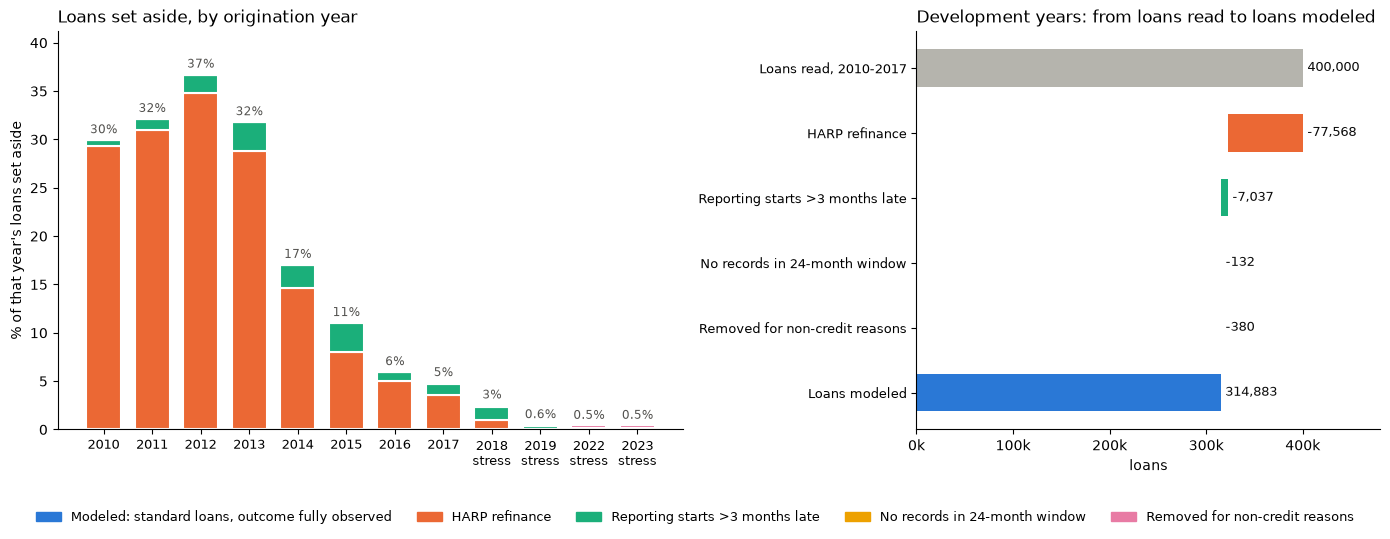

In [3]:
pm.plot_population(population, STRESS_YEARS, TEST_YEAR, MAX_FIRST_REPORT_MONTH, "images/loan_population.png")

**What we found**
- Of 400,000 loans made in 2010–2017, **314,883 are modeled**. The rest are mostly HARP refinances, which are about a third of 2010–2013 loans and almost vanish by 2018.
- HARP loans are different: all lack DTI, a fifth have LTV above 100%, and they default at 1.43% against 0.41% for standard loans. Keeping them would teach the model about a product that no longer exists.
- Loans whose reporting starts late would make defaults look rarer than they are, because their riskiest early months are hidden.

## 2. What drives default risk?

Before modeling, a look at the raw default rates by year, credit score, LTV and DTI (2010–2017 loans only for the bands).

vintage,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2022,2023
loans,34981.0,33883.00,31590.00,34049.00,41428.00,44434.00,46975.00,47543.00,48700.00,49714.00,49755.00,49751.00
defaults,105.0,80.00,44.00,78.00,133.00,197.00,288.00,372.00,1252.00,2283.00,890.00,875.00
default rate %,0.3,0.24,0.14,0.23,0.32,0.44,0.61,0.78,2.57,4.59,1.79,1.76


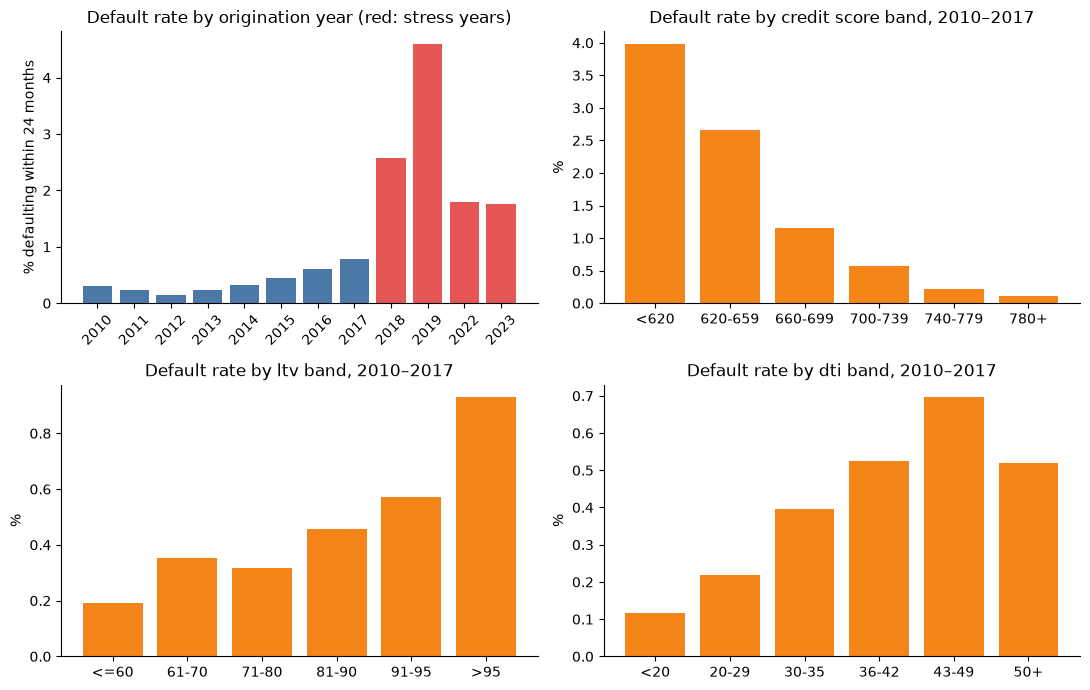

In [4]:
dev = loans[loans.vintage <= TEST_YEAR]
by_year = loans.groupby("vintage").agg(loans=("default", "size"), defaults=("default", "sum"), default_rate=("default", "mean"))
display(by_year.assign(default_rate=lambda t: (t.default_rate * 100).round(2)).rename(columns={"default_rate": "default rate %"}).T)
pm.plot_risk_profile(loans, by_year, STRESS_YEARS, TEST_YEAR, "images/eda_default_rates.png")

**What we found**
- **Defaults are rare:** 0.41% of 2010–2017 loans, about 1 in 250. This imbalance shapes how we judge the model (section 4) and set cutoffs (section 5).
- **Credit score is the strongest signal:** risk falls steeply as the score rises. Risk also rises with LTV and DTI.
- **Default rates rose every year from 2012 (0.14%) to 2017 (0.78%)**, so later years are riskier than the training years. The stress years (red) are much higher still: COVID in 2018–2019, rising rates in 2022–2023.

## 3. Two models: which one wins?

We split by **year**, not at random, so the model is always tested on loans made after the ones it learned from:

| Set | Years | Used for |
|---|---|---|
| Train | 2010–2015 | fitting the models |
| Validation | 2016 | choosing settings and picking the winner |
| Test | 2017 | final score, used once |
| Stress test | 2018–2019, 2022–2023 | seeing how the finished model copes with shocks (section 6) |

Two models compete:
- **Logistic regression:** the traditional, transparent choice. Each factor adds or subtracts a fixed amount of risk.
- **Gradient boosting:** a more flexible model that can learn curves and interactions. It is constrained so that risk can only fall as credit score rises, and only rise with LTV, CLTV and DTI.

The model with the better AUC on 2016 becomes the **champion**. The 2017 test year plays no part in that choice.

In [5]:
assert set(pm.FEATURES) <= pm.ALLOW_LIST, "A feature outside the origination allow-list slipped in"
train = loans[loans.vintage.isin(TRAIN_YEARS)]
valid = loans[loans.vintage == VALID_YEAR]
test = loans[loans.vintage == TEST_YEAR]
X_tr, y_tr = train[pm.FEATURES], train["default"]
X_va, y_va = valid[pm.FEATURES], valid["default"]
X_te, y_te = test[pm.FEATURES], test["default"]
display(pd.DataFrame({"loans": [len(train), len(valid), len(test)], "defaults": [y_tr.sum(), y_va.sum(), y_te.sum()],
                      "default rate %": [round(y.mean() * 100, 2) for y in (y_tr, y_va, y_te)]},
                     index=["train 2010-15", "valid 2016", "test 2017"]))

logit = pm.make_logit().fit(X_tr, y_tr)
gbm, gbm_settings, search_tbl = pm.tune_gbm(X_tr, y_tr, X_va, y_va, SEED)
valid_auc = {"Logistic regression": pm.roc_auc_score(y_va, logit.predict_proba(X_va)[:, 1]),
             "Gradient boosting": pm.roc_auc_score(y_va, gbm.predict_proba(X_va)[:, 1])}
CHAMPION = max(valid_auc, key=valid_auc.get)
champion = {"Logistic regression": logit, "Gradient boosting": gbm}[CHAMPION]
display(pd.Series(valid_auc, name="2016 validation AUC").round(4).to_frame())
print(f"Champion: {CHAMPION}")

,loans,defaults,default rate %
train 2010-15,220365,637,0.29
valid 2016,46975,288,0.61
test 2017,47543,372,0.78


,2016 validation AUC
Logistic regression,0.8284
Gradient boosting,0.8184


Champion: Logistic regression


**What we found**
- **Logistic regression wins** (AUC 0.828 vs 0.818 on 2016).
- The likely reason: after cleaning, there are only 637 defaults to learn from. A flexible model like boosting picks up patterns that turn out to be noise; logistic regression is too simple to do that. With far more data, boosting often wins.

## 4. How good is the model?

**Calibration first.** A model can rank loans well and still get the size of the risk wrong. We adjust the champion's probabilities using 2016, choosing between two standard methods (Platt scaling and isotonic regression) on held-out data.

**Then the test on 2017**, loans the model has never seen. Because defaults are so rare, **accuracy is a misleading measure**: a model that says "nobody defaults" is 99.2% accurate and useless. We use measures that focus on finding the rare defaulters:
- **AUC, Gini, KS:** how well the model ranks risky loans above safe ones
- **PR-AUC:** how well it finds defaulters (a random model would score the default rate, 0.008)
- **Brier score:** how accurate the probabilities are (lower is better)

,ROC-AUC,Gini,KS,PR-AUC,Brier,avg predicted PD %,actual default rate %
Logistic regression (raw),0.8188,0.6377,0.5194,0.0371,0.0077,0.4810,0.7824
Gradient boosting (raw),0.7967,0.5933,0.4778,0.0350,0.0077,0.4738,0.7824
Champion (Logistic regression) + platt calibration,0.8188,0.6377,0.5194,0.0371,0.0076,0.8478,0.7824


Boosting minus logistic regression: -4.4 Gini points (95% CI -6.6 to -2.3)


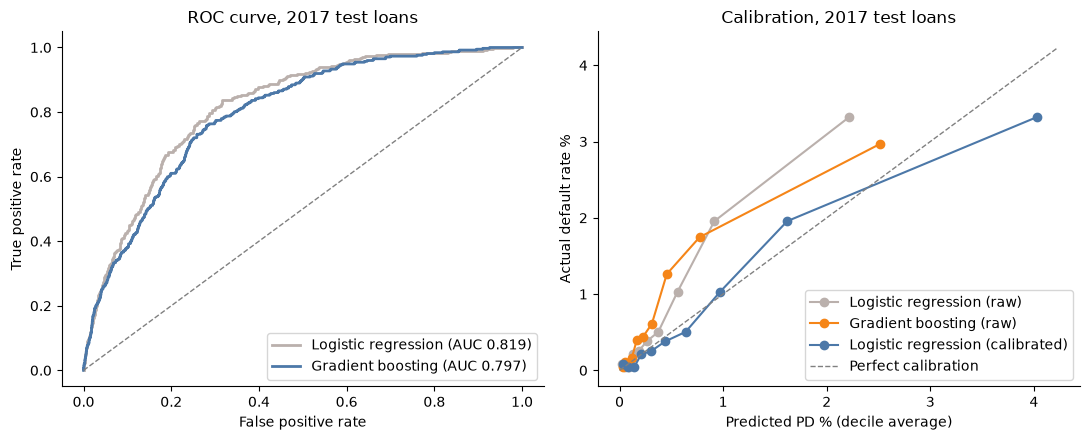

In [6]:
calibrator, chosen_cal, cal_tbl = pm.choose_calibration(champion.predict_proba(X_va)[:, 1], y_va, SEED)

y_arr = y_te.to_numpy()
p_te_logit = logit.predict_proba(X_te)[:, 1]
p_te_gbm = gbm.predict_proba(X_te)[:, 1]
p_te_champ = calibrator.transform(champion.predict_proba(X_te)[:, 1])
results_tbl = pd.DataFrame({"Logistic regression (raw)": pm.metrics(y_arr, p_te_logit),
                            "Gradient boosting (raw)": pm.metrics(y_arr, p_te_gbm),
                            f"Champion ({CHAMPION}) + {chosen_cal} calibration": pm.metrics(y_arr, p_te_champ)}).T
display(results_tbl.round(4))

auc_gap, gap_ci = pm.bootstrap_auc_gap(y_arr, p_te_gbm, p_te_logit, SEED)
print(f"Boosting minus logistic regression: {2*auc_gap*100:+.1f} Gini points (95% CI {2*gap_ci[0]*100:+.1f} to {2*gap_ci[1]*100:+.1f})")
pm.plot_roc_calibration(y_arr, p_te_logit, p_te_gbm, p_te_champ, CHAMPION, "images/roc_and_calibration.png")

**Risk bands.** Sort the 2017 loans by predicted PD and cut them into ten equal groups. A useful model packs the defaults into the top groups.

In [7]:
band_tbl = pm.risk_band_table(y_arr, p_te_champ)
display(band_tbl)
top20_capture = band_tbl["cumulative % of defaults"].iloc[1] / 100
print(f"The riskiest 20% of loans contain {top20_capture:.0%} of all defaults")

,loans,avg predicted PD %,actual default rate %,% of all defaults,cumulative % of defaults
band,,,,,
1,4755,4.03,3.32,42.47,42.47
2,4754,1.62,1.96,25.00,67.47
3,4754,0.97,1.03,13.17,80.65
4,4754,0.64,0.50,6.45,87.10
5,4755,0.44,0.38,4.84,91.94
6,4754,0.31,0.25,3.23,95.16
7,4754,0.21,0.21,2.69,97.85
8,4754,0.14,0.04,0.54,98.39
9,4754,0.08,0.04,0.54,98.92


The riskiest 20% of loans contain 67% of all defaults


**What we found**
- **AUC 0.82 on 2017**, and logistic regression beats boosting by a margin that isn't noise (the confidence interval excludes zero).
- **The probabilities are about right:** 0.85% predicted vs 0.78% actual, and the calibration chart tracks the diagonal.
- **Defaults concentrate at the top:** the riskiest 10% of loans default at 3.3% (four times the average), and the riskiest 20% hold 67% of all defaults. The safest half default at about 0.1%.

## 5. Where to draw the line: catching bad loans vs turning away good borrowers

The model gives every applicant a PD. Deciding **which PD is too high** is a business choice, and it is a trade-off:
- **Flag more applicants** and you catch more future defaults, but you also turn away (or slow down) good borrowers, and a mortgage that is repaid is income the bank loses.
- **Flag fewer** and you keep that income, but take on more losses.

**What we do about the imbalance.** We deliberately do **not** rebalance the data (no oversampling, no class weights). Those tricks make the model's probabilities wrong, and a bank needs true probabilities to price loans and set capital. Instead, the imbalance is handled where it belongs: in **choosing the cutoff**. The table and chart below show what each cutoff buys on the 2017 loans.

,PD cutoff %,defaults caught %,good borrowers flagged %,good borrowers per default caught,"default rate, flagged %","default rate, approved %"
flag the riskiest,,,,,,
2%,5.10,13.98,1.91,17.29,5.47,0.69
5%,3.35,28.76,4.81,21.22,4.50,0.59
10%,2.18,42.47,9.75,29.09,3.32,0.50
20%,1.22,67.47,19.63,36.88,2.64,0.32
30%,0.78,80.65,29.60,46.54,2.10,0.22


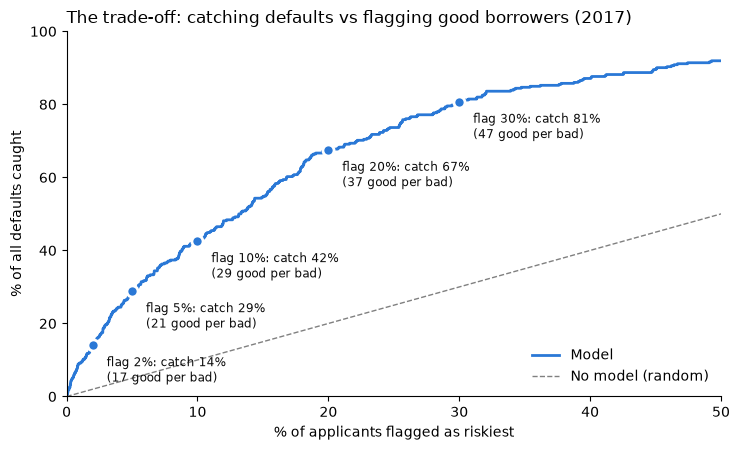

In [8]:
cut_tbl = pm.cutoff_table(y_arr, p_te_champ)
display(cut_tbl.round(2))
pm.plot_cutoffs(y_arr, p_te_champ, cut_tbl, "images/cutoffs.png")

**Putting money on it.** A bank should decline a loan only when the expected loss is bigger than the expected profit:

> decline if PD × (loss if it defaults) > (1 − PD) × (profit if it's repaid)

That gives a **breakeven PD** = profit ÷ (profit + loss). Two inputs are assumptions, not data, so we try a range:
- **Loss if it defaults (LGD):** 20–40% of the loan. Mortgages are backed by the house, so a default loses only part of the balance.
- **Profit if repaid:** 1–2% of the loan over the two-year horizon.

The last column is the money saved on the 2017 sample loans (about $11 billion of mortgages) by declining everyone above the breakeven PD, compared with approving everyone.

In [9]:
breakeven_tbl = pm.breakeven_table(y_arr, p_te_champ, test["orig_upb"].to_numpy(), lgd_options=[0.20, 0.30, 0.40], margin_options=[0.01, 0.02])
display(breakeven_tbl.round(2))

,loss if default (LGD) %,"profit if repaid, 2 yrs %",breakeven PD %,applicants above it %,defaults caught,defaults in total,"net saving vs approving all, $m"
0,20.0,1.0,4.76,2.38,60,372,0.53
1,20.0,2.0,9.09,0.34,16,372,0.25
2,30.0,1.0,3.23,5.35,110,372,2.22
3,30.0,2.0,6.25,1.14,35,372,0.40
4,40.0,1.0,2.44,8.52,141,372,4.67
5,40.0,2.0,4.76,2.38,60,372,1.07


**What we found: the right balance**
- **Catching every bad loan is not worth it.** To catch two-thirds of defaults, the bank would flag 20% of applicants: about **37 good borrowers for every default caught**.
- **On the economics, outright declines should be rare:** only applicants with a PD above roughly **2–9%** (depending on the loss and profit assumptions), which is **0.3–9% of applicants**. Because a mortgage is secured by a house, a default costs a fraction of the loan, while turning away a good borrower loses the whole relationship.
- **A practical policy uses three tiers**, the way mortgage lenders actually work:
  1. **Approve** the large majority (PD below about 1%).
  2. **Review or price up** the middle: manual underwriting, a larger down payment, or a higher rate for higher risk. This keeps the income while covering the risk.
  3. **Decline** only the small group above the breakeven PD.
- The exact cutoffs should be set by the bank's own loss and profit figures; this section shows how to read them off the model.

## 6. Stress test: does the model hold up when conditions change?

We take the finished model (nothing refit) and score loans whose first two years hit a shock:

| Years | Shock | What happened |
|---|---|---|
| 2018–2019 | **COVID** | Job losses from 2020, and widespread forbearance (payments paused by agreement) |
| 2022–2023 | **Rising rates** | Mortgage rates rose from about 3% to over 7% |

Two questions: does the model still **rank** risky loans first (AUC)? And is the **level** of its probabilities still right? For COVID years we also show default rates with forbearance-period delinquency set aside.

,scenario,loans,defaults,actual default rate %,avg predicted PD %,AUC champion,AUC boosting,KS champion,top-20% capture %,actual rate excl. forbearance %,AUC excl. forbearance,median rate %
year,,,,,,,,,,,,
2017,Normal (test),47543,372,0.782,0.848,0.819,0.797,0.519,67.473,0.713,0.827,4.180
2018,COVID,48700,1252,2.571,1.106,0.728,0.715,0.340,50.080,0.739,0.783,4.750
2019,COVID,49714,2283,4.592,0.835,0.700,0.689,0.291,42.751,1.223,0.707,4.125
2022,Rising rates,49755,890,1.789,1.444,0.778,0.765,0.423,59.101,1.497,0.783,5.250
2023,Rising rates,49751,875,1.759,2.363,0.795,0.782,0.457,61.943,1.522,0.804,6.750


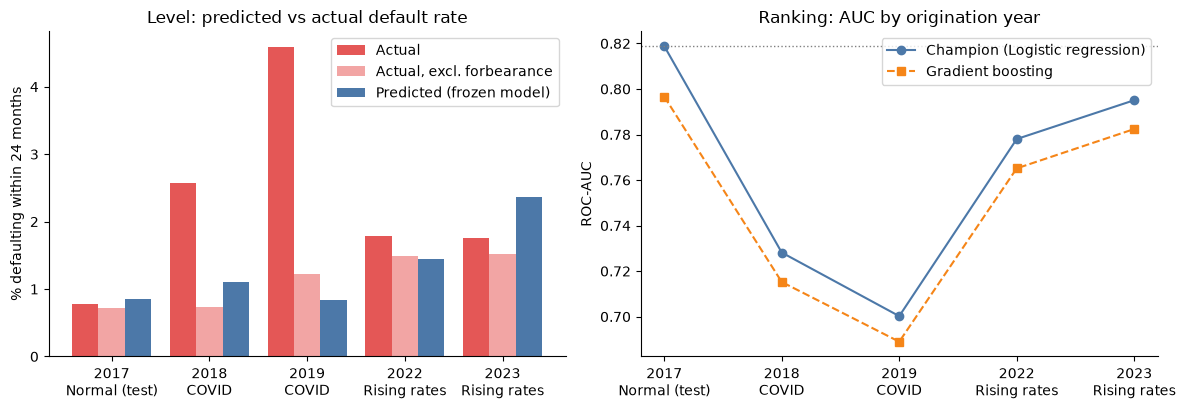

In [10]:
stress_tbl = pm.stress_table(loans, [TEST_YEAR] + list(STRESS_YEARS), STRESS_YEARS, champion, calibrator, gbm)
display(stress_tbl.round(3))
pm.plot_stress(stress_tbl, TEST_YEAR, CHAMPION, "images/stress_test.png")

**What we found**
- **COVID (2018–2019): both level and ranking break.** Default rates jumped to 2.6% and 4.6% (1.1% and 0.8% predicted). About 70% of those were paused payments under forbearance; without them, rates were 0.7% and 1.2%. Ranking weakened (AUC 0.73 and 0.70) because COVID job losses hit particular industries and places, which no application data can see.
- **Rising rates (2022–2023): ranking holds, the level drifts.** AUC stays at 0.78–0.80. The model overpredicts 2023 (2.4% vs 1.8%) because it uses the raw interest rate, and 2023 rates (median 6.75%) are far above anything it was trained on.
- **Logistic regression beats boosting in every stress year.**
- **Takeaway:** the ranking can support approvals in normal conditions; the probability levels must be watched and recalibrated whenever conditions shift.

## 7. Validity checks: does the model only use information available at approval?

A model is only trustworthy if it learns from information a bank would actually have when approving the loan. Using anything from later ("leakage") makes results look better than they would be in practice. Three checks:
1. **No payment history in the inputs.** The model sees only the 16 application fields; a check stops the notebook if anything else slips in (it ran in section 3).
2. **Nothing is fitted on the test year.** Models are fitted on 2010–2015; settings, the winner and calibration come from 2016; 2017 and the stress years are only scored.
3. **Overlapping time.** Each loan is followed for 24 months, so the outcomes of 2015–2016 loans run into 2017–2018, the same years the 2017 test loans are living through. A bank in early 2017 wouldn't have seen those outcomes yet. Below, we refit using only outcomes available by early 2017 (train 2010–2013, calibrate 2014) and compare.

In [11]:
strict_tr = loans[loans.vintage.isin(range(2010, 2014))]
strict_ca = loans[loans.vintage == 2014]
strict_model = clone(logit).fit(strict_tr[pm.FEATURES], strict_tr["default"])
overlap_tbl = pd.DataFrame({
    "Current: train 2010-15, calibrate 2016": pm.overlap_row(logit, X_va, y_va, int(y_tr.sum()), X_te, y_arr),
    "Strict: train 2010-13, calibrate 2014": pm.overlap_row(strict_model, strict_ca[pm.FEATURES], strict_ca["default"],
                                                           int(strict_tr["default"].sum()), X_te, y_arr),
}).T
display(overlap_tbl.round({"2017 AUC": 4, "avg predicted PD %": 3, "actual default rate %": 3, "Brier": 5}))

,training defaults,2017 AUC,avg predicted PD %,actual default rate %,Brier
"Current: train 2010-15, calibrate 2016",637.0,0.8188,0.848,0.782,0.00765
"Strict: train 2010-13, calibrate 2014",307.0,0.8056,0.386,0.782,0.00769


**What we found**
- **The ranking is genuine:** AUC barely moves (0.819 → 0.806), and the strict model has half as many defaults to learn from.
- **The probability level relies on recent outcomes:** with only early-2017 information, the model would have predicted 0.39% against the actual 0.78%. So the close match in section 4 means "accurate once recalibrated on recent outcomes", not "forecast in advance". Banks recalibrate as new outcomes arrive, the same lesson as the stress test.

## 8. Inside the model: what drives a prediction?

**Which factors matter most?** Shuffle one factor at a time on the 2017 loans and see how much the AUC drops. **Which way do they push?** The partial-dependence curves show average predicted risk as credit score, LTV and DTI change.

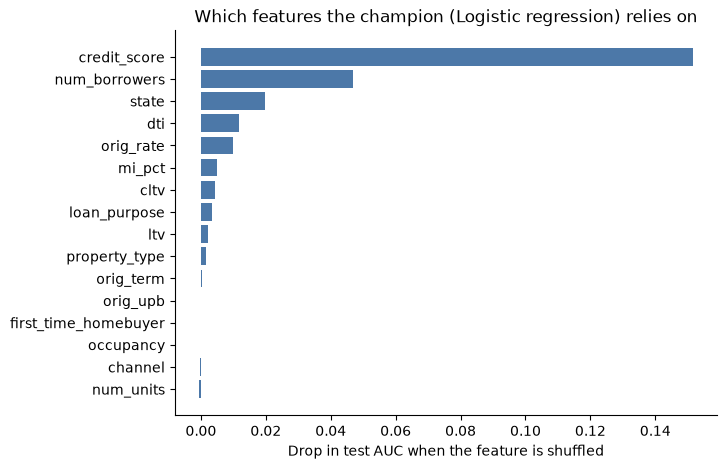

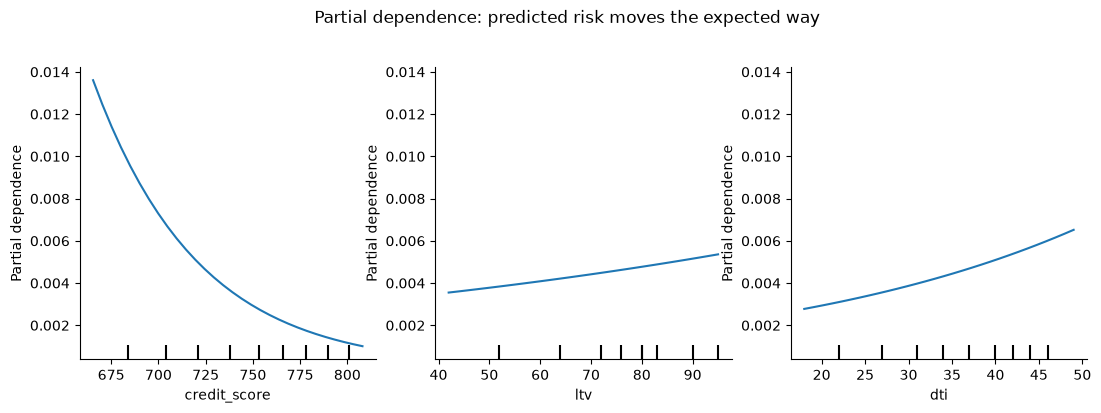

In [12]:
imp = pm.plot_drivers(champion, X_te, y_te, CHAMPION, SEED, "images/feature_importance.png", "images/partial_dependence.png")

**Example applications.** A typical 2017 application, then one change at a time. Linked fields change together, as in real underwriting: a higher LTV comes with mortgage insurance, a lower credit score with a higher rate. These applications are **hypothetical**, built from aggregate statistics; a check confirms none matches a real loan. The **risk band** places each PD among 2017 loans (band 1 = riskiest 10%).

In [13]:
base = {"credit_score": 748, "ltv": 80, "cltv": 80, "dti": 36, "orig_rate": 4.125, "orig_upb": 228000, "orig_term": 360,
        "mi_pct": 0, "num_units": 1, "num_borrowers": 2, "loan_purpose": "P", "occupancy": "P", "property_type": "SF",
        "channel": "R", "first_time_homebuyer": "N", "state": "OH"}
lower_score = {"credit_score": 684, "orig_rate": 4.375}
higher_ltv = {"ltv": 95, "cltv": 95, "mi_pct": 30}
higher_dti = {"dti": 45}
one_borrower = {"num_borrowers": 1}
scenarios = {
    "Base case": {},
    "Credit score 684 (rate 4.375%)": lower_score,
    "LTV 95% (with 30% mortgage insurance)": higher_ltv,
    "DTI 45%": higher_dti,
    "Single borrower": one_borrower,
    "All four changes together": {**lower_score, **higher_ltv, **higher_dti, **one_borrower},
}
examples = pd.DataFrame([{**base, **change} for change in scenarios.values()], index=list(scenarios))

# Safeguard: no hypothetical application may coincide with a real loan in the data
matches = examples[pm.FEATURES].astype(str).merge(loans[pm.FEATURES].astype(str).drop_duplicates(), how="inner")
assert matches.empty, "A hypothetical application matches a real loan; change its values"

examples["PD %"] = calibrator.transform(champion.predict_proba(examples[pm.FEATURES])[:, 1]) * 100
examples["x base case"] = examples["PD %"] / examples.loc["Base case", "PD %"]
examples["risk band (2017)"] = [int(np.clip(np.ceil((p_te_champ > p / 100).mean() * 10), 1, 10)) for p in examples["PD %"]]
display(examples[["credit_score", "ltv", "dti", "num_borrowers", "orig_rate", "PD %", "x base case", "risk band (2017)"]]
        .round({"PD %": 2, "x base case": 1}))
print("None of the hypothetical applications matches a loan in the dataset.")

,credit_score,ltv,dti,num_borrowers,orig_rate,PD %,x base case,risk band (2017)
Base case,748,80,36,2,4.125,0.22,1.0,7
Credit score 684 (rate 4.375%),684,80,36,2,4.375,0.82,3.8,3
LTV 95% (with 30% mortgage insurance),748,95,36,2,4.125,0.42,1.9,5
DTI 45%,748,80,45,2,4.125,0.28,1.3,6
Single borrower,748,80,36,1,4.125,0.68,3.1,4
All four changes together,684,95,45,1,4.375,6.16,28.4,1


None of the hypothetical applications matches a loan in the dataset.


**What we found**
- **Credit score matters most**, then the number of borrowers (two incomes are a cushion), state, DTI and the interest rate.
- Risk moves the expected way: down as credit score rises, up with LTV and DTI.
- **Risks multiply:** a lower score (3.8×), higher LTV (1.9×), higher DTI (1.3×) and a single borrower (3.1×) combine to about 28× the base PD. Few real loans stack this many risks, so PDs for such profiles deserve a manual look.